# 02 · Joining 311 requests to census tracts

**Goal:** Tracts come from the Census and carry the ACS demographics (e.g., limited-English households). They cover all of LA County, including cities other than LA. 311 requests come as latitude/longitude points and should all lie within the City of LA. So we match each point to its tract, then keep only tracts that are mostly inside the city (at least 50%).


In [31]:
import duckdb, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50, "display.width", 140)
con = duckdb.connect()
RAW, PROC = "../data/raw", "../data/processed"


## 1. Load the three inputs

In [32]:
req = con.sql(f"""
    SELECT sr_number, lat, lon FROM '{PROC}/requests_clean.parquet' WHERE NOT no_coords
""").df()
tracts = gpd.read_file(f"{RAW}/tl_2023_06_tract/tl_2023_06_tract.shp")
tracts = tracts[tracts.COUNTYFP == "037"][["GEOID", "ALAND", "geometry"]]   # LA County only
places = gpd.read_file(f"{RAW}/tl_2023_06_place/tl_2023_06_place.shp")
city = places[places.GEOID == "0644000"]                                      # City of Los Angeles
acs = pd.read_csv(f"{RAW}/acs5_2023_la_tracts.csv", dtype={"geoid": str})
# The Census encodes "no data" as huge negative numbers (e.g. -666666666). Treat them as missing.
num = acs.select_dtypes("number").columns
acs[num] = acs[num].mask(acs[num] < -1e8)
print(len(req), "requests with coordinates |", len(tracts), "county tracts |", len(acs), "ACS rows")
print("tract CRS:", tracts.crs)

4112224 requests with coordinates | 2498 county tracts | 2498 ACS rows
tract CRS: EPSG:4269


**Data-quality catch:** the first run of this notebook showed a median income of about −$666 million. The Census uses large negative codes (e.g. `-666666666`) to mean "not available" (too few sample households). Treating them as real numbers would have silently ruined every income comparison, so we convert them to missing. Always run `.describe()` on a column before trusting it.

**Check:** county tract count (2,498) equals the ACS row count. The Census tract file and the ACS data use the same 2020 boundaries, so the IDs should line up.

In [33]:
print("tract IDs in boundary file but not ACS:", len(set(tracts.GEOID) - set(acs.geoid)))
print("tract IDs in ACS but not boundary file:", len(set(acs.geoid) - set(tracts.GEOID)))

tract IDs in boundary file but not ACS: 0
tract IDs in ACS but not boundary file: 0


## 2. Which tracts are "in" the City of LA?
311 only covers the city, but tracts don't follow the city line. A tract half inside Santa Monica would show few requests *per household* just because half its households aren't in the city. So for each tract we measure **what fraction of its area lies inside the City of LA** (done in an equal-area projection so areas are accurate).

In [34]:
t_area = tracts.to_crs(3310)                       # California Albers, an equal-area projection
c_area = city.to_crs(3310)
t_area["tract_area"] = t_area.area
inter = gpd.overlay(t_area[["GEOID", "tract_area", "geometry"]], c_area[["geometry"]], how="intersection")
inter["frac_in_city"] = inter.area / inter["tract_area"]
overlap = tracts[["GEOID"]].merge(inter[["GEOID", "frac_in_city"]], on="GEOID", how="left").fillna({"frac_in_city": 0})
overlap["frac_in_city"].describe()

geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 201 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


count    2498.000000
mean        0.444194
std         0.495904
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: frac_in_city, dtype: float64

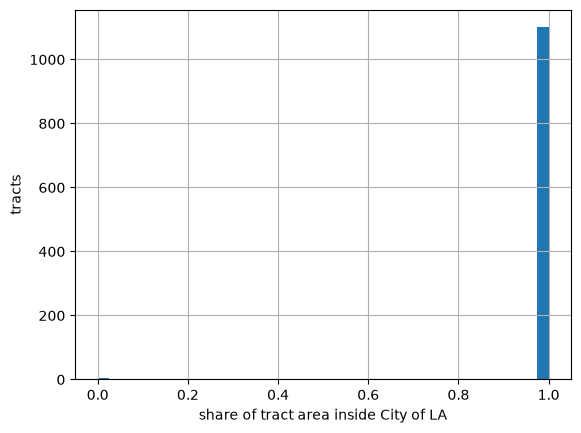

fully inside (>=99%): 1100 | partial (1–99%): 17 | outside: 1381


In [35]:
ax = overlap.query("frac_in_city > 0")["frac_in_city"].hist(bins=40)
ax.set_xlabel("share of tract area inside City of LA"); ax.set_ylabel("tracts"); plt.show()
print("fully inside (>=99%):", (overlap.frac_in_city >= .99).sum(),
      "| partial (1–99%):", overlap.frac_in_city.between(.01, .99).sum(),
      "| outside:", (overlap.frac_in_city <= .01).sum())

Most tracts are either fully inside or fully outside, with a minority straddling the boundary. **Decision:** keep tracts with **at least 50% of their area in the city** and flag the partial ones so we can test whether dropping them changes results.

In [36]:
CITY_CUTOFF = 0.5
city_tracts = overlap[overlap.frac_in_city >= CITY_CUTOFF].GEOID
print(len(city_tracts), "tracts kept as City of LA")

1110 tracts kept as City of LA


## 3. The spatial join: point → tract
`within` means the point must fall inside the polygon. Points exactly on a border could match two tracts, so we check for duplicates afterwards.

In [37]:
pts = gpd.GeoDataFrame(req[["sr_number"]], geometry=gpd.points_from_xy(req.lon, req.lat), crs=tracts.crs)
joined = gpd.sjoin(pts, tracts[["GEOID", "geometry"]], how="left", predicate="within")
print("rows before:", len(pts), "after:", len(joined))
joined = joined.drop_duplicates("sr_number")      # border points can match twice; keep one
req_tract = pd.DataFrame(joined[["sr_number", "GEOID"]]).rename(columns={"GEOID": "geoid"})
print("matched to a tract:", req_tract.geoid.notna().sum(), "| unmatched:", req_tract.geoid.isna().sum())

rows before: 4112224 after: 4112224
matched to a tract: 4112224 | unmatched: 0


**Checks:** (1) the row count didn't grow after dropping border duplicates; (2) unmatched points are those outside LA County (bad coordinates). Let's see how many requests land in our city tracts.

In [38]:
req_tract["in_city_tract"] = req_tract.geoid.isin(city_tracts)
print(req_tract.in_city_tract.mean().round(4), "of geocoded requests fall in City-of-LA tracts")
print(req_tract.groupby("in_city_tract").size())

0.9966 of geocoded requests fall in City-of-LA tracts
in_city_tract
False      14038
True     4098186
dtype: int64


A small share of requests fall outside the city's tracts (the city serves a few areas outside its boundary, plus GPS noise). We keep only city tracts for analysis.

## 4. Attach the ACS demographics and sanity-check the result

In [39]:
acs["lep_hh"] = acs[["C16002_004E","C16002_007E","C16002_010E","C16002_013E"]].sum(axis=1)
acs["lep_share"] = acs.lep_hh / acs.C16002_001E
tr = (overlap.merge(acs[["geoid","NAME","C16002_001E","lep_hh","lep_share","B19013_001E",
                          "B25003_001E","B25003_003E","B01003_001E"]],
                    left_on="GEOID", right_on="geoid", how="left")
          .rename(columns={"GEOID":"geoid_","C16002_001E":"households","B19013_001E":"median_income",
                           "B25003_003E":"renter_hh","B25003_001E":"occupied","B01003_001E":"population"}))
tr = tr[tr.geoid_.isin(city_tracts)].drop(columns="geoid").rename(columns={"geoid_":"geoid"})
tr["renter_share"] = tr.renter_hh / tr.occupied
# Extra controls for the models: ALAND is land area in square meters
tr["pop_density"] = tr.population / (tr.geoid.map(tracts.set_index("GEOID").ALAND) / 1e6)   # people per sq km
tr["hh_size"] = tr.population / tr.households.where(tr.households > 0)                      # people per household
tr[["households","median_income","lep_share","renter_share","pop_density","hh_size"]].describe().round(2)

,households,median_income,lep_share,renter_share,pop_density,hh_size
count,1110.00,1093.00,1103.00,1103.00,1110.00,1103.00
mean,1275.80,87214.43,0.15,0.63,6672.60,3.17
std,484.97,41127.48,0.11,0.26,5452.72,7.00
min,0.00,7000.00,0.00,0.00,0.00,1.17
25%,953.25,57708.00,0.05,0.44,3262.70,2.24
50%,1232.50,78750.00,0.12,0.67,5423.30,2.78
75%,1560.25,106587.00,0.22,0.84,8530.84,3.33
max,4919.00,250001.00,0.71,1.00,46862.89,186.14


In [40]:
counts = req_tract[req_tract.in_city_tract].groupby("geoid").size().rename("n_requests")
tr = tr.merge(counts, left_on="geoid", right_index=True, how="left").fillna({"n_requests": 0})
tr["req_per_hh"] = tr.n_requests / tr.households
print("tracts with zero requests:", (tr.n_requests == 0).sum())
print("tracts with <100 households:", (tr.households < 100).sum(), "| missing income:", tr.median_income.isna().sum())
tr.sort_values("n_requests", ascending=False).head(5)[["geoid","households","n_requests","req_per_hh","lep_share"]]

tracts with zero requests: 0
tracts with <100 households: 16 | missing income: 17


,geoid,households,n_requests,req_per_hh,lep_share
2039,06037226002,1209,14493,11.987593,0.073615
57,06037206051,1011,12044,11.912957,0.025717
6,06037206050,753,11289,14.992032,0.306773
2247,06037224020,936,10370,11.079060,0.217949
2038,06037226001,598,10160,16.989967,0.322742


**Sanity check:** the tracts with the highest request counts should be dense places with lots of dumping or graffiti. Do any outliers look like data errors (e.g., a tract with 100+ requests per household)?

In [41]:
tr.req_per_hh.replace([float("inf")], float("nan")).describe().round(2)

count    1103.00
mean        3.58
std         7.60
min         0.05
25%         2.07
50%         2.92
75%         3.92
max       151.60
Name: req_per_hh, dtype: float64

## 5. Look at the pattern: requests per household vs. limited-English share

We split tracts into 5 equal-sized groups by `lep_share` (lowest 20% to highest 20%) and compare the **median** requests per household in each group. We use the median because a few extreme tracts would drag the mean. Tracts with fewer than 100 households are excluded because their ratios are unstable.

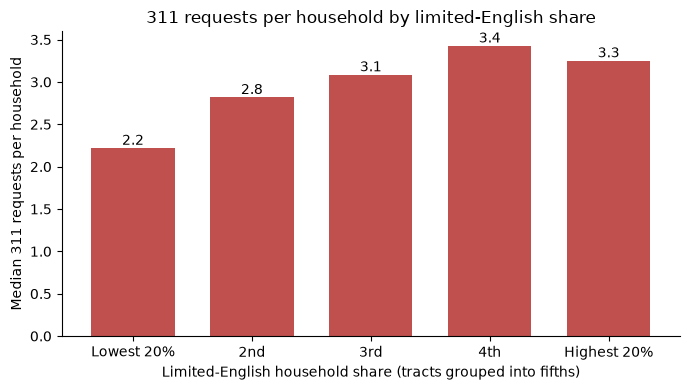

1094 tracts plotted


In [42]:
d = (tr.replace([float("inf")], float("nan"))
         .dropna(subset=["lep_share", "req_per_hh"])
         .query("households >= 100").copy())
labels = ["Lowest 20%", "2nd", "3rd", "4th", "Highest 20%"]
d["lep_group"] = pd.qcut(d.lep_share, 5, labels=labels)
by = d.groupby("lep_group", observed=True).req_per_hh.median()

ax = by.plot.bar(color="#c0504d", width=0.7, figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f")
ax.set_xlabel("Limited-English household share (tracts grouped into fifths)")
ax.set_ylabel("Median 311 requests per household")
ax.set_title("311 requests per household by limited-English share")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(len(d), "tracts plotted")

Trachs with higher limited-English share show higher, not lower, median 311 requests per household (2.2 in the lowest fifth vs. about 3.3 in the highest). This runs against our expectation of underuse

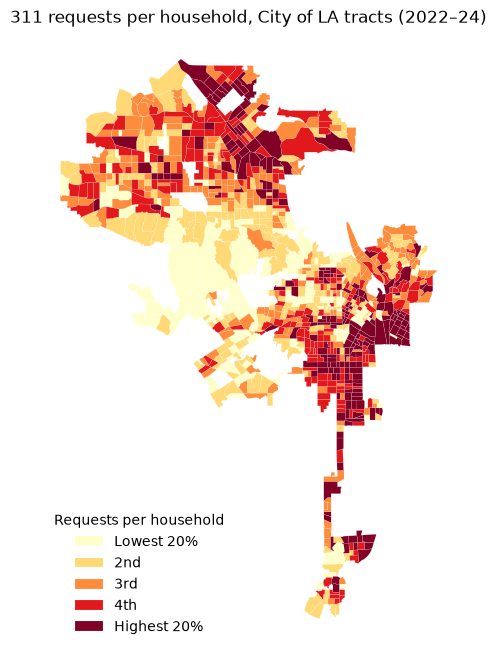

In [43]:
# Map: same idea, but 5 equal-sized color bins instead of a continuous scale
g = tracts.merge(d[["geoid", "req_per_hh"]], left_on="GEOID", right_on="geoid", how="inner")
g["bin"] = pd.qcut(g.req_per_hh, 5, labels=["Lowest 20%", "2nd", "3rd", "4th", "Highest 20%"])
ax = g.plot(column="bin", categorical=True, cmap="YlOrRd", legend=True, figsize=(8, 8),
            edgecolor="white", linewidth=0.1,
            legend_kwds={"title": "Requests per household", "loc": "lower left", "frameon": False})
ax.set_title("311 requests per household, City of LA tracts (2022–24)"); ax.axis("off")
plt.show()

### Does the pattern survive a control? (renter share)
Limited-English share moves together with renter share, and renters may file differently. To check, we split tracts into three renter-share groups and repeat the comparison *within* each. If the rise in requests only came from renter share, the lines below would be flat.

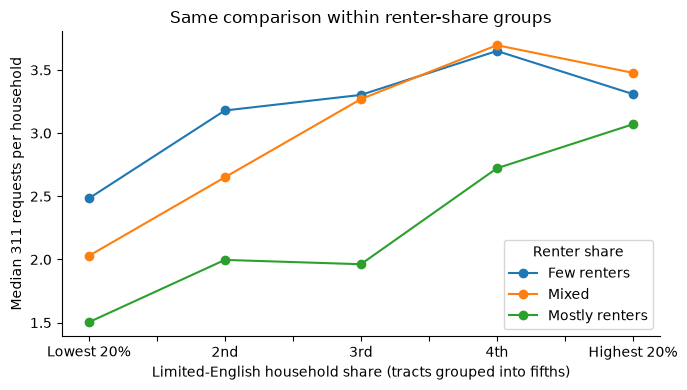

tracts per cell (small cells are noisy):
renter_group  Few renters  Mixed  Mostly renters
lep_group                                       
Lowest 20%            115     64              40
2nd                   109     66              44
3rd                    85     82              51
4th                    44     90              85
Highest 20%            12     62             145


In [44]:
d2 = d.dropna(subset=["renter_share"]).copy()
d2["renter_group"] = pd.qcut(d2.renter_share, 3, labels=["Few renters", "Mixed", "Mostly renters"])
med = d2.pivot_table(index="lep_group", columns="renter_group", values="req_per_hh",
                     aggfunc="median", observed=True)
n = d2.pivot_table(index="lep_group", columns="renter_group", values="req_per_hh",
                   aggfunc="size", observed=True)

ax = med.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Limited-English household share (tracts grouped into fifths)")
ax.set_ylabel("Median 311 requests per household")
ax.set_title("Same comparison within renter-share groups")
ax.legend(title="Renter share"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("tracts per cell (small cells are noisy):"); print(n)

To account for renter share as a possible confounder, we divided tracts into three groups: few renters, mixed, and mostly renters. Tracts with mostly renters have fewer requests per household at every level of limited-English share, possibly because landlords or property managers handle some problems instead of tenants calling 311 (an untested explanation). Even so, within each group, requests per household still rise as the limited-English share increases.

Raw comparisons do not support our hypothesis that limited-English tracts file fewer requests: requests per household rise with limited-English share, even within renter-share groups. However, request counts also reflect how many problems a tract has, which we have not yet measured. We cannot conclude that limited-English share has no effect until the models control for factors like density and income.

## 6. Save for the next notebooks

In [45]:
req_tract.to_parquet(f"{PROC}/request_tract.parquet", index=False)
tr.to_parquet(f"{PROC}/tracts_city.parquet", index=False)
print("saved", len(req_tract), "request→tract rows and", len(tr), "city tracts")

saved 4112224 request→tract rows and 1110 city tracts
